In [ ]:
# Tester at Frost API fungerer

import requests
from pathlib import Path

# Leser Client ID fra tekstfilen på PC-en din
client_id_file = Path.home() / "frost_client_id.txt"
client_id = client_id_file.read_text().strip()

# Frost API-endepunktet for observasjoner
url = "https://frost.met.no/observations/v0.jsonld"

# Velger værstasjon, tidsperiode og værdata
parameters = {
    "sources": "SN17850",
    "referencetime": "2024-01-01/2024-01-03",
    "elements": "air_temperature"
}

# Sender forespørselen til Frost API
response = requests.get(
    url,
    params=parameters,
    auth=(client_id, ""),
    timeout=30
)

# Viser resultatet av testen
print("Statuskode:", response.status_code)

if response.status_code == 200:
    print("Frost API fungerer!")
    print(response.json()["data"][:1])
else:
    print(response.text[:1000]) 
    



Statuskode: 200
Frost API fungerer!
[{'sourceId': 'SN17850:0', 'referenceTime': '2024-01-01T00:00:00.000Z', 'observations': [{'elementId': 'air_temperature', 'value': -3.7, 'unit': 'degC', 'level': {'levelType': 'height_above_ground', 'unit': 'm', 'value': 1}, 'timeOffset': 'PT0H', 'timeResolution': 'PT1H', 'timeSeriesId': 0, 'performanceCategory': 'C', 'exposureCategory': '1', 'qualityCode': 2}, {'elementId': 'air_temperature', 'value': -3.7, 'unit': 'degC', 'level': {'levelType': 'height_above_ground', 'unit': 'm', 'value': 50}, 'timeOffset': 'PT0H', 'timeResolution': 'PT1H', 'timeSeriesId': 0, 'performanceCategory': 'C', 'exposureCategory': '1', 'qualityCode': 2}, {'elementId': 'air_temperature', 'value': -3.7, 'unit': 'degC', 'level': {'levelType': 'height_above_ground', 'unit': 'm', 'value': 2}, 'timeOffset': 'PT0H', 'timeResolution': 'PT1H', 'timeSeriesId': 0, 'performanceCategory': 'C', 'exposureCategory': '1', 'qualityCode': 0}]}]


## Task 1: Temperature
### Following the example from frost.met.no on how to get the data when using Python

In [17]:
# Requesting the daily mean air temperature for 2025

print("Starting Frost request...")

import requests
from pathlib import Path

# Read Client ID from file
client_id_file = Path.home() / "frost_client_id.txt"
client_id = client_id_file.read_text().strip()

# Frost API endpoint
url = "https://frost.met.no/observations/v0.jsonld"

## Parameters for Ås and all of 2025
parameters = {
    "sources": "SN17850",
    "referencetime": "2025-01-01/2026-01-01",
    "elements": "mean(air_temperature P1D)"
}

# Send request to Frost API
response = requests.get(
    url,
    params=parameters,
    auth=(client_id, ""),
    timeout=30
)

print("Frost response received!")

# Check response status
print("Status code:", response.status_code)

if response.status_code == 200:
    data = response.json()["data"]
    print("Frost API works!")
    print("Number of observations:", len(data))

    ## Extract dates and daily mean temperatures
    dates = []
    temperatures = []

    for item in data:
        dates.append(item["referenceTime"])
        temperatures.append(item["observations"][0]["value"])

    print("Temperatures extracted:", len(temperatures))

else:
    print("Error:", response.text[:1000]) 

Starting Frost request...
Frost response received!
Status code: 200
Frost API works!
Number of observations: 365
Temperatures extracted: 365


### Make plot of air temperature: 

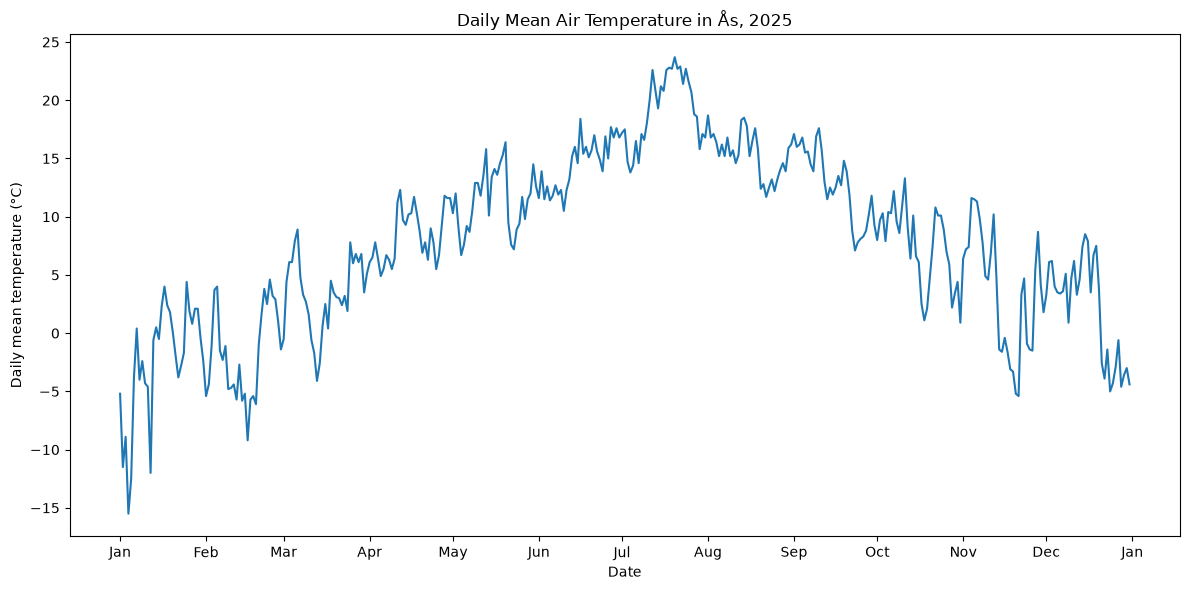

In [18]:
import matplotlib.pyplot as plt

# Plot daily mean temperature for 2025
plt.figure(figsize=(12, 6))
plt.plot(dates, temperatures)

plt.xlabel("Date")
plt.ylabel("Daily mean temperature (°C)")
plt.title("Daily Mean Air Temperature in Ås, 2025")

# Show one date label per month
# --> tried it without this part and the x-axis was very crowded, so I added this to make it more readable 
import matplotlib.dates as mdates

plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b"))




plt.tight_layout() #Automatically adjusts the spacing around the graph
plt.show()

### Calculate the mean, median, min and max temperature for this year (2025)

In [19]:
import statistics

## Calculate summary statistics for 2025:
mean_temp = statistics.mean(temperatures)
median_temp = statistics.median(temperatures)
min_temp = min(temperatures)
max_temp = max(temperatures)

### Make the summary table containing the summary statistics

In [ ]:
# Display summary table: 

print("Summary of daily mean air temperature in Ås, 2025:")
print("-------------------------------------------------")
print("Mean temperature:", round(mean_temp, 2), "°C")
print("Median temperature:", round(median_temp, 2), "°C")
print("Minimum temperature:", round(min_temp, 2), "°C")
print("Maximum temperature:", round(max_temp, 2), "°C")

Summary of daily mean air temperature in Ås, 2025:
-------------------------------------------------
Mean temperature: 7.87 °C
Median temperature: 8.3 °C
Minimum temperature: -15.5 °C
Maximum temperature: 23.7 °C


## Task 2: Precipitation

In [21]:
# Requesting daily precipitation for 2025

import requests
from pathlib import Path

# Read Client ID from file
client_id_file = Path.home() / "frost_client_id.txt"
client_id = client_id_file.read_text().strip()

# Frost API endpoint
url = "https://frost.met.no/observations/v0.jsonld"

# Parameters for Ås and all of 2025
parameters = {
    "sources": "SN17850",
    "referencetime": "2025-01-01/2026-01-01",
    "elements": "sum(precipitation_amount P1D)"
}

# Send request to Frost API
precipitation_response = requests.get(
    url,
    params=parameters,
    auth=(client_id, ""),
    timeout=30
)

# Check response status
print("Status code:", precipitation_response.status_code)

if precipitation_response.status_code == 200:
    precipitation_data = precipitation_response.json()["data"]

    # Extract dates and daily precipitation amounts
    precipitation_dates = []
    precipitation_values = []

    for item in precipitation_data:
        precipitation_dates.append(item["referenceTime"])
        precipitation_values.append(item["observations"][0]["value"])

    print("Frost API works!")
    print("Number of precipitation observations:", len(precipitation_values))

else:
    print("Error:", precipitation_response.text[:1000])


Status code: 200
Frost API works!
Number of precipitation observations: 365


### Create a new plot that shows both the temperature from task 1 and the precipitation in the same plot
Creating one figure showing both the temperature from task 1 and the precipitation from task 2.
Going to use two y-axes; one for temperature and one for precipitation. 

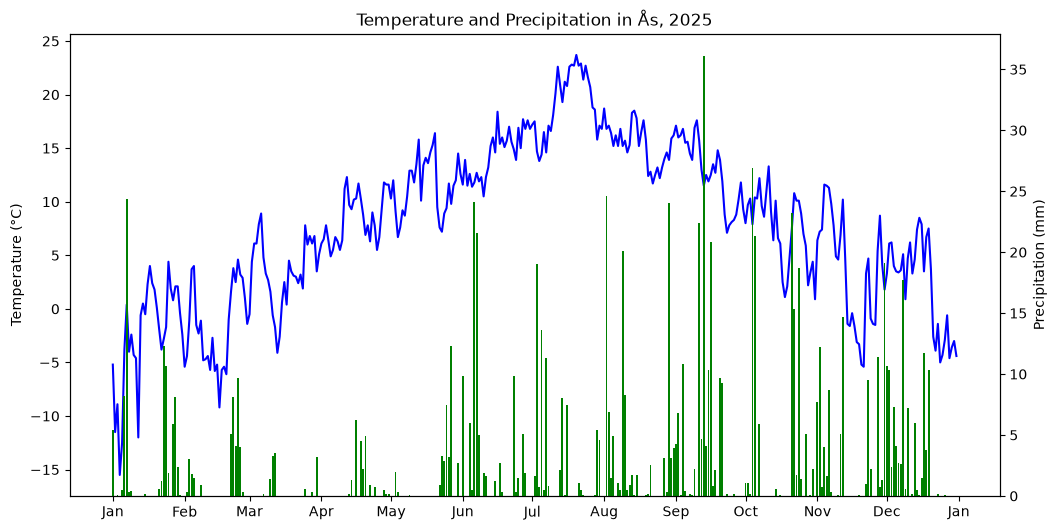

In [24]:
import matplotlib.pyplot as plt

# Create the plot
fig, ax1 = plt.subplots(figsize=(12, 6))  # making the first y-axis for temperature
# subplots(figsize=(12, 6)) Creates a figure in which we will plot our graph

# Plot temperature as a line
ax1.plot(dates, temperatures, color="blue", label="Temperature")
ax1.set_ylabel("Temperature (°C)")

# Plot precipitation as bars
ax2 = ax1.twinx() # making the other y-axis for precipitation
ax2.bar(precipitation_dates, precipitation_values, color="green", label="Precipitation")
ax2.set_ylabel("Precipitation (mm)")


# Show one date label per month
"""Matplotlib tries to display too many dates, causing them to overlap
To fix this we can use the MonthLocator and DateFormatter to show only one date label per month."""
ax1.xaxis.set_major_locator(mdates.MonthLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b"))



plt.title("Temperature and Precipitation in Ås, 2025")
plt.show()

--> A line graph works best for temperature (blue)
--> A bar chart works best for precipitation (green)

## Task 3: Historical temperature data
### Now we are going to compare the 2025 temperatures to the 1925 temperatures 


### 1. Get the temperature data from 1925:
Using the same "recipe" on getting data from Frost API, only this time we must change the year number to 1925, instead of 2025.
We also change the variable-names to distinguish the historical data from the temperature data for 2025, (f.ex: response --> historical_response)

In [25]:
# Requesting daily temperature data for 1925

parameters = {
    "sources": "SN17850",
    "referencetime": "1925-01-01/1926-01-01",
    "elements": "mean(air_temperature P1D)"
}

historical_response = requests.get(
    url,
    params=parameters,
    auth=(client_id, "")
)

print("Status code:", historical_response.status_code)

if historical_response.status_code == 200:
    historical_data = historical_response.json()["data"]

# Creates two new empty lists for the data from 1925:
    historical_dates = []
    historical_temperatures = []

    for item in historical_data:
        historical_dates.append(item["referenceTime"])
        historical_temperatures.append(item["observations"][0]["value"])

Status code: 200


In [ ]:
# Checking how many observations we got for 1925:

print("Number of observations:", len(historical_data))

Number of observations: 365


### 2. Create the comparison graph 
The new and the old temperatures in the same graph

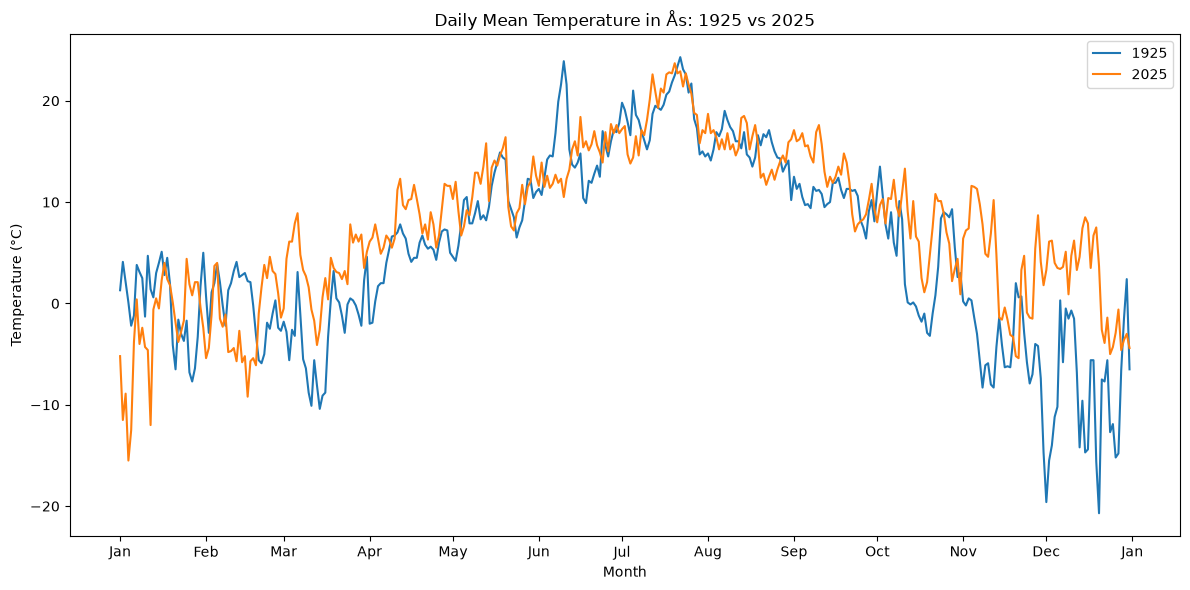

In [27]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime

# Change the year in the historical dates to 2025
comparison_dates = []

for date in historical_dates:
    new_date = datetime.fromisoformat(date.replace("Z", "+00:00"))
    comparison_dates.append(new_date.replace(year=2025))

# Convert the 2025 dates to datetime objects
temperature_dates = []

for date in dates:
    temperature_dates.append(datetime.fromisoformat(date.replace("Z", "+00:00")))

# Plot temperatures from both years
plt.figure(figsize=(12, 6))

# Comparing the daily mean temperatures from 1925 and 2025
plt.plot(comparison_dates, historical_temperatures, label="1925")
plt.plot(temperature_dates, temperatures, label="2025")

plt.xlabel("Month")
plt.ylabel("Temperature (°C)")
plt.title("Daily Mean Temperature in Ås: 1925 vs 2025")
plt.legend()

# Show one date label per month
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b"))

plt.tight_layout()
plt.show()


### Conclusion of the reusult from the comparison graph: 

The temperature patterns throughout the year are quite similar in 1925 and 2025, 
--> with low temperatures in winter and higher temperatures in summer. 

However, temperatures in 2025 are slightly higher than in 1925. 
The temperatures in 1925 appear to fluctuate more, with several extremely cold days. 

In [28]:
# Calculate summary statistics

import statistics

# Calculate summary statistics for 1925:
mean_temp_1925 = statistics.mean(historical_temperatures)
median_temp_1925 = statistics.median(historical_temperatures)
min_temp_1925 = min(historical_temperatures)
max_temp_1925 = max(historical_temperatures)



# Calculate summary statistics for 2025:
mean_temp_2025 = statistics.mean(temperatures)
median_temp_2025 = statistics.median(temperatures)
min_temp_2025 = min(temperatures)
max_temp_2025 = max(temperatures)




In [29]:
# Display summary table for 1925 (the old temperatures) and 2025 (the new temperatures):

print("Summary of daily mean air temperature in Ås:")
print("-------------------------------------------------")
print("Statistic          | 1925       | 2025")
print("-------------------------------------------------")
print("Mean temperature   |", round(mean_temp_1925, 2), "°C |", round(mean_temp_2025, 2), "°C")
print("Median temperature |", round(median_temp_1925, 2), "°C |", round(median_temp_2025, 2), "°C")
print("Minimum temperature|", round(min_temp_1925, 2), "°C |", round(min_temp_2025, 2), "°C")
print("Maximum temperature|", round(max_temp_1925, 2), "°C |", round(max_temp_2025, 2), "°C")

Summary of daily mean air temperature in Ås:
-------------------------------------------------
Statistic          | 1925       | 2025
-------------------------------------------------
Mean temperature   | 5.28 °C | 7.87 °C
Median temperature | 5.3 °C | 8.3 °C
Minimum temperature| -20.7 °C | -15.5 °C
Maximum temperature| 24.3 °C | 23.7 °C


### Conclusion from the summary table: 

We can see that the average temperature has increased from 1925 to 2025, suggesting that it has generally become warmer.

## Task 4: Heatwaves 

In [30]:
import requests
from pathlib import Path

# Read Client ID from file
client_id_file = Path.home() / "frost_client_id.txt"
client_id = client_id_file.read_text().strip()

# Frost API endpoint
url = "https://frost.met.no/observations/v0.jsonld"

# Parameters for Ås and all of 2025
parameters = {
    "sources": "SN17850",
    "referencetime": "2025-01-01/2026-01-01",
    "elements": "max(air_temperature P1D)"
}


# Send request to Frost API
response = requests.get(
    url,
    params=parameters,
    auth=(client_id, ""),
    timeout=30
)

# Check response status
print("Status code:", response.status_code)

if response.status_code == 200:    # Checking if the request to Frost API was successful (status code 200 means OK)
    data = response.json()["data"] # Making the answer to data python can read, getting out the part called "data" and making it into a variable called data

    # Extract dates and daily maximum temperatures
    heatwave_dates = []
    max_temperatures = []


    for item in data:
        """Here, we go through the weather data one observation at a time 
        and extract the date and maximum temperature:"""

        heatwave_dates.append(item["referenceTime"])              # Retrieves the date from the observation and adds it to the heatwave_dates list
        max_temperatures.append(item["observations"][0]["value"]) # Retrieves the maximum temperature and adds it to the max_temperatures list, [0]= the first observation

    print("Frost API works!")
    print("Number of observations:", len(max_temperatures))

else:
    print("Error:", response.text[:1000]) 

Status code: 200
Frost API works!
Number of observations: 365


--> This code gets out the max-temperatures per day from Ås, 2025 and 
stores the data in two lists: heatwave_dates and max_temperatures

### Write a function that counts the number of heatwaves in a year: 

In [31]:
# Function to count heatwaves

def count_heatwaves(max_temperatures):
    """
    
    Count heatwaves based on daily maximum temperatures
    Arguments:
        max_temperatures: A list of daily maximum temperatures in Celsius.

    Returns:
        The number of heatwaves found.

    """
    heatwaves = 0
    consecutive_days = 0  # Counts consecutive days with temperatures of at least 27 celsius

    for temperature in max_temperatures:
        if temperature >= 27:
            consecutive_days = consecutive_days + 1
        else:
            if consecutive_days >= 5:
                heatwaves = heatwaves + 1

            consecutive_days = 0

    if consecutive_days >= 5:
        heatwaves = heatwaves + 1

    return heatwaves

In [32]:
# Now we need to count the heatwaves in Ås in 2025 and print the result. 


number_of_heatwaves = count_heatwaves(max_temperatures)

print("Number of heatwaves in Ås in 2025:", number_of_heatwaves)

Number of heatwaves in Ås in 2025: 1


### Result:
There was just one heatwave in Ås 2025 based on the maximum-temperatures we retrieved from Frost API 


### Next step: Finish up task 4 - Heatwaves 
The task requires the function to work with any station ID and year, and to write the heatwave dates and station information to a YAML file. 

The plan: 
Create a new complete function in a new code-cell that performs the entire task


In [33]:
# The complete function 
import yaml
from pathlib import Path

def create_heatwave_summary(station_id, year):
    """
    Find heatwaves for a station and year and save them to a YAML file.

    A heatwave is at least five consecutive days with a maximum
    temperature of 27 degrees Celsius or higher.

    Args:
        station_id: The ID of the weather station.
        year: The year to investigate.
    """
    # Read the Frost API Client ID
    client_id_file = Path.home() / "frost_client_id.txt"
    client_id = client_id_file.read_text().strip()


 # Get maximum temperatures from Frost API
    parameters = {
        "sources": station_id,
        "referencetime": f"{year}-01-01/{year + 1}-01-01",
        "elements": "max(air_temperature P1D)"
    }

    response = requests.get(
        url,
        params=parameters,
        auth=(client_id, ""),
        timeout=30
    )
    response.raise_for_status()
    data = response.json()["data"]


     # Find the station name
    station_response = requests.get(
        "https://frost.met.no/sources/v0.jsonld",
        params={"ids": station_id},
        auth=(client_id, ""),
        timeout=30
    )
    station_response.raise_for_status()
    station_name = station_response.json()["data"][0]["name"]

    # Find heatwave dates
    dates = []
    start_date = None
    previous_date = None
    consecutive_days = 0

    for item in data:
        current_date = item["referenceTime"][:10]
        temperature = item["observations"][0]["value"]

        if temperature >= 27:
            if consecutive_days == 0:
                start_date = current_date

            consecutive_days += 1

        else:
            if consecutive_days >= 5:
                dates.append(f"{start_date} - {previous_date}")

            consecutive_days = 0
            start_date = None

        previous_date = current_date

# Check if a heatwave ends on the last day
    if consecutive_days >= 5:
        dates.append(f"{start_date} - {previous_date}")

    # Write the summary to a YAML file
    summary = {
        "dates": dates,
        "station_id": station_id,
        "station_name": station_name,
        "year": year
    }

    with open(f"heatwaves_{station_id}_{year}.yml", "w", encoding="utf-8") as file:
        yaml.dump(summary, file, allow_unicode=True, sort_keys=False)

    print("Heatwave summary saved.")

In [ ]:
# Test of the function we made to find heatwaves and save them to a YAML file.

create_heatwave_summary("SN17850", 2025) 
# --> It tests whether the function works when asked to examine weather station Ås (SN17850) for the year 2025.

Heatwave summary saved.


### We got out: Heatwave summary saved
--> This means that the function ran without errors and wrote a YAML file.

### Now we need to chech that the function works with any station name/id and year
We will be doing two tests: 
   Test 1: Ås in 2024 – checks whether a different year works.
   Test 2: Another weather station in 2025 – checks whether a different station works.

In [35]:
# Test 1 (Ås station in 2024)
create_heatwave_summary("SN17850", 2024)

Heatwave summary saved.


Test 1 is complited! 
The message "Heatwave summary saved." means that the function has run and saved the YAML file for Ås in 2024.

Check the YAML file: 
--> contains the year 2024

In [ ]:
# Test 2 (Another weather station in 2025)
create_heatwave_summary("SN18700", 2025)

Heatwave summary saved.


Test 2 is complited! 
The message #Heatwave summary saved." means that the function has run and saved the YAML file for another weather station than Ås. 

Check the YAML file: 
--> contains weather station: "station_name: OSLO - BLINDERN"


## Task 5 - Moving average temperature


In [ ]:
# Function to calculate the 7-day moving average

def moving_average(temperatures):
    """
    Calculate the 7-day moving average of a list of temperatures.
    
    Args:
        temperatures: A list of daily mean temperatures in Celsius.
    
    Returns:
        A list of 7-day moving averages.
    """
    moving_averages = []

    for i in range(len(temperatures) - 6):
        seven_days = temperatures[i:i + 7]
        average = sum(seven_days) / 7
        moving_averages.append(average)

    return moving_averages

In [38]:
# Calculate the 7-day moving average for 2025

moving_averages = moving_average(temperatures)

print("Number of daily temperatures:", len(temperatures))
print("Number of moving averages:", len(moving_averages))


Number of daily temperatures: 365
Number of moving averages: 359


### Making the plot: 
Showing the moving average as a line and the daily temperature as
points

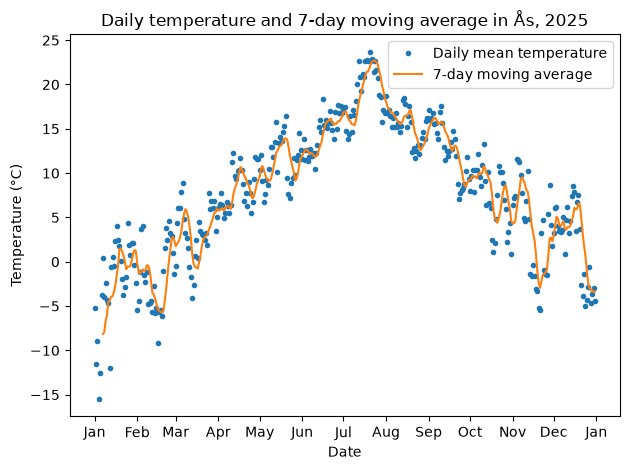

In [40]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Plot daily temperatures as points
plt.plot(dates, temperatures, ".", label="Daily mean temperature")

# Plot the 7-day moving average as a line
plt.plot(dates[6:], moving_averages, label="7-day moving average")

# Format the x-axis to show one date per month
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b"))

# Add labels and title
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.title("Daily temperature and 7-day moving average in Ås, 2025")

plt.legend()
plt.tight_layout()
plt.show()